# Pre-processing the Adult Dataset

## 0. Setup

In [122]:
import json
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

stats = {}

FIG_DIR = pathlib.Path("figures")
FIG_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "font.size": 10,
})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.1


In [123]:
df_raw = pd.read_csv("adult.csv")
df = df_raw.copy()        

stats["n_rows"] = int(df.shape[0])
stats["n_cols"] = int(df.shape[1])
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 48,842 rows x 15 columns


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


## 1.1 Descriptive statistics for the numerical features

In [124]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]

print("Numerical  :", num_cols)
print("Categorical:", cat_cols)

desc = pd.DataFrame({
    "count":  df[num_cols].count(),
    "mean":   df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode":   df[num_cols].mode().iloc[0],
    "std":    df[num_cols].std(),
    "var":    df[num_cols].var(),
    "min":    df[num_cols].min(),
    "max":    df[num_cols].max(),
    "skew":   df[num_cols].skew(),
    "kurtosis": df[num_cols].kurtosis(),
})

desc["cv"] = desc["std"] / desc["mean"]
desc.round(3)

Numerical  : ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country', 'income']


,count,mean,median,mode,std,var,min,max,skew,kurtosis,cv
age,48842,38.644,37.0,36,13.711,1.879780e+02,17,90,0.558,-0.184,0.355
fnlwgt,48842,189664.135,178144.5,203488,105604.025,1.115221e+10,12285,1490400,1.439,6.058,0.557
educational-num,48842,10.078,10.0,9,2.571,6.610000e+00,1,16,-0.317,0.626,0.255
capital-gain,48842,1079.068,0.0,0,7452.019,5.553259e+07,0,99999,11.895,152.693,6.906
capital-loss,48842,87.502,0.0,0,403.005,1.624127e+05,0,4356,4.570,20.014,4.606
hours-per-week,48842,40.422,40.0,40,12.391,1.535480e+02,1,99,0.239,2.951,0.307


In [125]:
stats["describe"] = desc.round(4).to_dict(orient="index")
skew_rank = desc["skew"].abs().sort_values(ascending=False)
stats["skew_rank"] = {k: round(float(v), 3) for k, v in skew_rank.items()}
skew_rank.round(3)

capital-gain       11.895
capital-loss        4.570
fnlwgt              1.439
age                 0.558
educational-num     0.317
hours-per-week      0.239
Name: skew, dtype: float64

In [126]:
stats["describe"] = desc.round(4).to_dict(orient="index")
skew_rank = desc["var"].abs().sort_values(ascending=False)
stats["var_rank"] = {k: round(float(v), 3) for k, v in skew_rank.items()}
skew_rank.round(3)

fnlwgt             1.115221e+10
capital-gain       5.553259e+07
capital-loss       1.624127e+05
age                1.879780e+02
hours-per-week     1.535480e+02
educational-num    6.610000e+00
Name: var, dtype: float64

### Interpretation — variance and skew

**Highest variance** 
- fnlwgt 

**Significant skew** 

* capital-gain
* capital-loss
* fnlwgt
* age

## 1.2 Data-quality audit

### 1.2.1 Data type of every column

In [127]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "kind": ["Numerical" if c in num_cols else "Categorical" for c in df.columns],
    "n_unique": df.nunique(),
})

audit

,dtype,kind,n_unique
age,int64,Numerical,74
workclass,str,Categorical,9
fnlwgt,int64,Numerical,28523
education,str,Categorical,16
educational-num,int64,Numerical,16
marital-status,str,Categorical,7
occupation,str,Categorical,15
relationship,str,Categorical,6
race,str,Categorical,5
gender,str,Categorical,2


In [128]:
stats["audit"] = audit.astype(str).to_dict(orient="index")
stats["n_numeric"] = len(num_cols)
stats["n_categorical"] = len(cat_cols)
print(f"{len(num_cols)} numerical columns, {len(cat_cols)} categorical columns")

6 numerical columns, 9 categorical columns


### 1.2.2 Missing values

In [129]:
sentinel = "?"
miss = pd.DataFrame({
    "n_missing": {c: int((df[c].astype(str).str.strip() == sentinel).sum()) for c in cat_cols}
})

stats["missing"] = miss.to_dict(orient="index")
stats["n_missing_total"] = int(miss["n_missing"].sum())
miss

,n_missing
workclass,2799
education,0
marital-status,0
occupation,2809
relationship,0
race,0
gender,0
native-country,857
income,0


In [133]:
mask = df[cat_cols].apply(lambda s: s.astype(str).str.strip() == sentinel)
rows_any = int(mask.any(axis=1).sum())
both_wc_occ = int((mask["workclass"] & mask["occupation"]).sum())

stats["rows_with_any_missing"] = rows_any
stats["pct_rows_with_any_missing"] = round(rows_any / len(df) * 100, 2)
stats["workclass_occupation_overlap"] = both_wc_occ

print(f"workclass and occupation both missing: {both_wc_occ:,}")

workclass and occupation both missing: 2,799


missingness is not random noise

- where workclass and occupation is missing has 2799 row that is 100% of workclass missing row so missing may cause by state of occupation like re-tired or exit.

In [96]:
n_dup = int(df.duplicated().sum())
stats["n_duplicates"] = n_dup
print(f"Fully duplicated rows: {n_dup}")

vc = df["income"].value_counts()
stats["target_counts"] = {k: int(v) for k, v in vc.items()}
stats["target_pos_rate"] = round(float((df["income"] == ">50K").mean()) * 100, 2)
print("\nTarget balance:")
print(vc)
print(f"\n>50K rate: {stats['target_pos_rate']} %  -> the classes are imbalanced (roughly 1:3).")

Fully duplicated rows: 52

Target balance:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64

>50K rate: 23.93 %  -> the classes are imbalanced (roughly 1:3).


## 1.3 Categorical analysis

### 1.3.1 Every distinct label in every categorical column

In [97]:
for c in cat_cols:
    labels = sorted(df[c].astype(str).str.strip().unique())
    print(f"\n{c}  ({len(labels)} distinct labels)")
    print("  " + ", ".join(labels))

stats["cat_levels"] = {
    c: sorted(df[c].astype(str).str.strip().unique().tolist()) for c in cat_cols
}
stats["cat_level_counts"] = {c: int(df[c].nunique()) for c in cat_cols}


workclass  (9 distinct labels)
  ?, Federal-gov, Local-gov, Never-worked, Private, Self-emp-inc, Self-emp-not-inc, State-gov, Without-pay

education  (16 distinct labels)
  10th, 11th, 12th, 1st-4th, 5th-6th, 7th-8th, 9th, Assoc-acdm, Assoc-voc, Bachelors, Doctorate, HS-grad, Masters, Preschool, Prof-school, Some-college

marital-status  (7 distinct labels)
  Divorced, Married-AF-spouse, Married-civ-spouse, Married-spouse-absent, Never-married, Separated, Widowed

occupation  (15 distinct labels)
  ?, Adm-clerical, Armed-Forces, Craft-repair, Exec-managerial, Farming-fishing, Handlers-cleaners, Machine-op-inspct, Other-service, Priv-house-serv, Prof-specialty, Protective-serv, Sales, Tech-support, Transport-moving

relationship  (6 distinct labels)
  Husband, Not-in-family, Other-relative, Own-child, Unmarried, Wife

race  (5 distinct labels)
  Amer-Indian-Eskimo, Asian-Pac-Islander, Black, Other, White

gender  (2 distinct labels)
  Female, Male

native-country  (42 distinct labels)


In [98]:
# Frequency of each label, as a proportion - useful for spotting rare categories.
for c in cat_cols:
    print(f"\n--- {c} ---")
    print((df[c].value_counts(normalize=True) * 100).round(2).head(10).to_string())


--- workclass ---
workclass
Private             69.42
Self-emp-not-inc     7.91
Local-gov            6.42
?                    5.73
State-gov            4.06
Self-emp-inc         3.47
Federal-gov          2.93
Without-pay          0.04
Never-worked         0.02

--- education ---
education
HS-grad         32.32
Some-college    22.27
Bachelors       16.43
Masters          5.44
Assoc-voc        4.22
11th             3.71
Assoc-acdm       3.28
10th             2.84
7th-8th          1.96
Prof-school      1.71

--- marital-status ---
marital-status
Married-civ-spouse       45.82
Never-married            33.00
Divorced                 13.58
Separated                 3.13
Widowed                   3.11
Married-spouse-absent     1.29
Married-AF-spouse         0.08

--- occupation ---
occupation
Prof-specialty       12.64
Craft-repair         12.51
Exec-managerial      12.46
Adm-clerical         11.49
Sales                11.27
Other-service        10.08
Machine-op-inspct     6.19
?           

### 1.3.2 `education` vs `educational-num` — why keeping both is redundant

In [99]:
edu_map = (df.groupby("education", observed=True)["educational-num"]
             .agg(["min", "max", "nunique", "size"])
             .sort_values("min"))
edu_map.columns = ["num_min", "num_max", "distinct_nums", "count"]
edu_map

,num_min,num_max,distinct_nums,count
education,,,,
Preschool,1,1,1,83
1st-4th,2,2,1,247
5th-6th,3,3,1,509
7th-8th,4,4,1,955
9th,5,5,1,756
10th,6,6,1,1389
11th,7,7,1,1812
12th,8,8,1,657
HS-grad,9,9,1,15784


In [100]:
# The mapping is one-to-one in both directions if each side has exactly one partner.
one_to_one = (df.groupby("education", observed=True)["educational-num"].nunique().max() == 1
              and df.groupby("educational-num")["education"].nunique().max() == 1)

stats["edu_one_to_one"] = bool(one_to_one)
stats["edu_levels"] = int(df["education"].nunique())
stats["edu_num_levels"] = int(df["educational-num"].nunique())
stats["edu_map"] = {str(k): int(v) for k, v in
                    df.groupby("education", observed=True)["educational-num"].first().items()}

print("education distinct levels      :", stats["edu_levels"])
print("educational-num distinct levels:", stats["edu_num_levels"])
print("Perfect one-to-one mapping     :", one_to_one)

education distinct levels      : 16
educational-num distinct levels: 16
Perfect one-to-one mapping     : True


**Explanation.** The table above shows a **perfect one-to-one mapping**: each of the 16
`education` labels corresponds to exactly one `educational-num` value, and vice versa
(`Preschool`→1, `1st-4th`→2, …, `Bachelors`→13, `Masters`→14, `Prof-school`→15,
`Doctorate`→16). The two columns therefore carry **exactly the same information** — they
are the same variable expressed twice, once as text and once as an integer code.

Keeping both is redundant, and actively harmful for modelling:

1. **Perfect multicollinearity.** Any model given both columns sees two features with a
   deterministic relationship. For linear models the coefficients become unidentifiable;
   for tree ensembles the feature importance of "education" is split arbitrarily between
   two identical columns.
2. **Wasted dimensionality.** One-hot encoding `education` alone would add 16 sparse
   columns that duplicate a single existing integer column.
3. **Loss of order.** `educational-num` already encodes the *rank* (a Doctorate outranks a
   Bachelors). One-hot encoding the text version would throw that ordering away.

**Decision:** drop `education` and keep `educational-num`, which is already a correct
ordinal encoding. Phase 3 verifies this by re-deriving the ordinal code from scratch with
an explicit rank order and checking it reproduces `educational-num` exactly.

---
# Phase 2 — Visual Discovery & Outlier Handling

**Goal:** use the visuals to *justify* a cleaning strategy rather than guess at one.

## 2.1 Histograms for `age`, `hours-per-week` and `capital-gain`

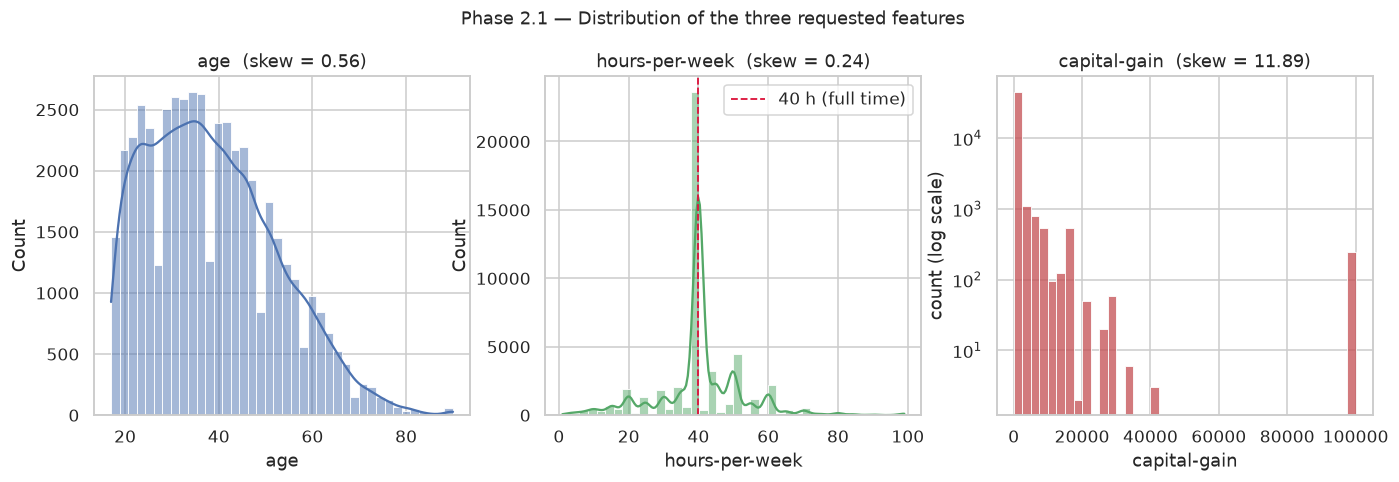

In [101]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["age"], bins=40, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"age  (skew = {df['age'].skew():.2f})")

sns.histplot(df["hours-per-week"], bins=40, kde=True, ax=axes[1], color="#55A868")
axes[1].set_title(f"hours-per-week  (skew = {df['hours-per-week'].skew():.2f})")
axes[1].axvline(40, color="crimson", ls="--", lw=1.2, label="40 h (full time)")
axes[1].legend()

sns.histplot(df["capital-gain"], bins=40, ax=axes[2], color="#C44E52")
axes[2].set_title(f"capital-gain  (skew = {df['capital-gain'].skew():.2f})")
axes[2].set_yscale("log")   # without a log y-axis only the zero bar is visible
axes[2].set_ylabel("count (log scale)")

fig.suptitle("Phase 2.1 — Distribution of the three requested features", y=1.03)
fig.savefig(FIG_DIR / "hist_three.png")
plt.show()

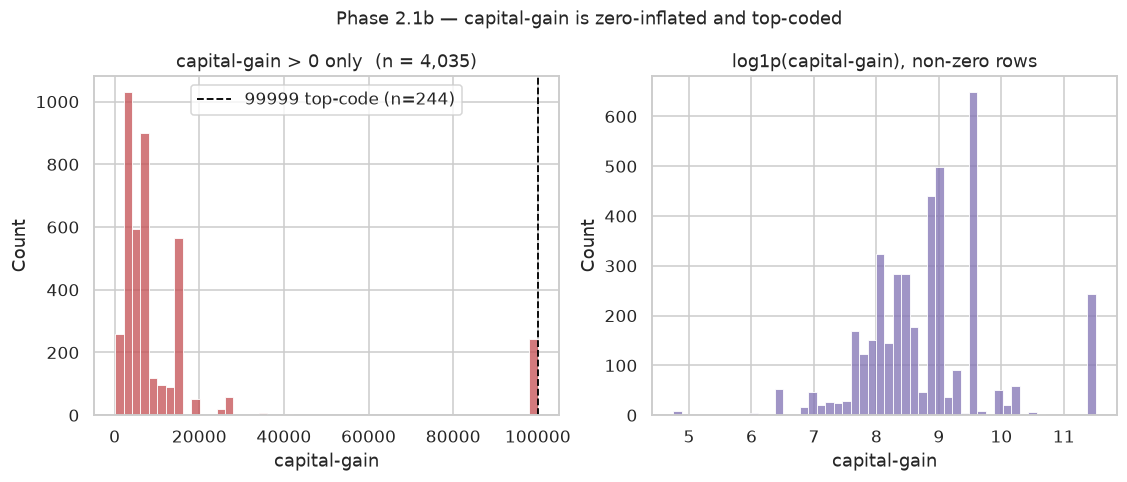

91.74 % of rows have capital-gain == 0
244 rows sit exactly on the 99,999 ceiling
Largest value below the ceiling: 41,310


In [102]:
# capital-gain deserves a closer look: it is zero-inflated, so plot the non-zero part alone.
nz = df.loc[df["capital-gain"] > 0, "capital-gain"]
zero_frac = float((df["capital-gain"] == 0).mean())
top_coded = int((df["capital-gain"] == 99999).sum())

stats["capgain_zero_pct"] = round(zero_frac * 100, 2)
stats["capgain_nonzero_n"] = int(len(nz))
stats["capgain_topcoded_n"] = top_coded
stats["capgain_max"] = int(df["capital-gain"].max())
stats["caploss_zero_pct"] = round(float((df["capital-loss"] == 0).mean()) * 100, 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(nz, bins=50, ax=axes[0], color="#C44E52")
axes[0].set_title(f"capital-gain > 0 only  (n = {len(nz):,})")
axes[0].axvline(99999, color="black", ls="--", lw=1.2, label=f"99999 top-code (n={top_coded})")
axes[0].legend()

sns.histplot(np.log1p(nz), bins=50, ax=axes[1], color="#8172B3")
axes[1].set_title("log1p(capital-gain), non-zero rows")

fig.suptitle("Phase 2.1b — capital-gain is zero-inflated and top-coded", y=1.03)
fig.savefig(FIG_DIR / "hist_capgain_zoom.png")
plt.show()

print(f"{zero_frac * 100:.2f} % of rows have capital-gain == 0")
print(f"{top_coded} rows sit exactly on the 99,999 ceiling")
print(f"Largest value below the ceiling: {nz[nz < 99999].max():,}")

**Reading the histograms.**

* **`age`** — right-skewed but perfectly plausible: a peak in the late twenties/thirties,
  a long thin tail into old age, hard-stopped at exactly 90.
* **`hours-per-week`** — a huge spike at exactly 40 (the standard working week), with
  smaller spikes at 20, 45, 50 and 60. It is not a smooth distribution but a mixture of
  socially conventional values. Values run from 1 to 99.
* **`capital-gain`** — visually almost a single bar at zero. On the log-count axis the tail
  becomes visible, and the zoomed plot shows a **separate cluster sitting exactly on
  99,999**: the value has been *top-coded*, i.e. every gain above the census cut-off was
  recorded as 99,999.

## 2.2 Box plots for the numerical variables

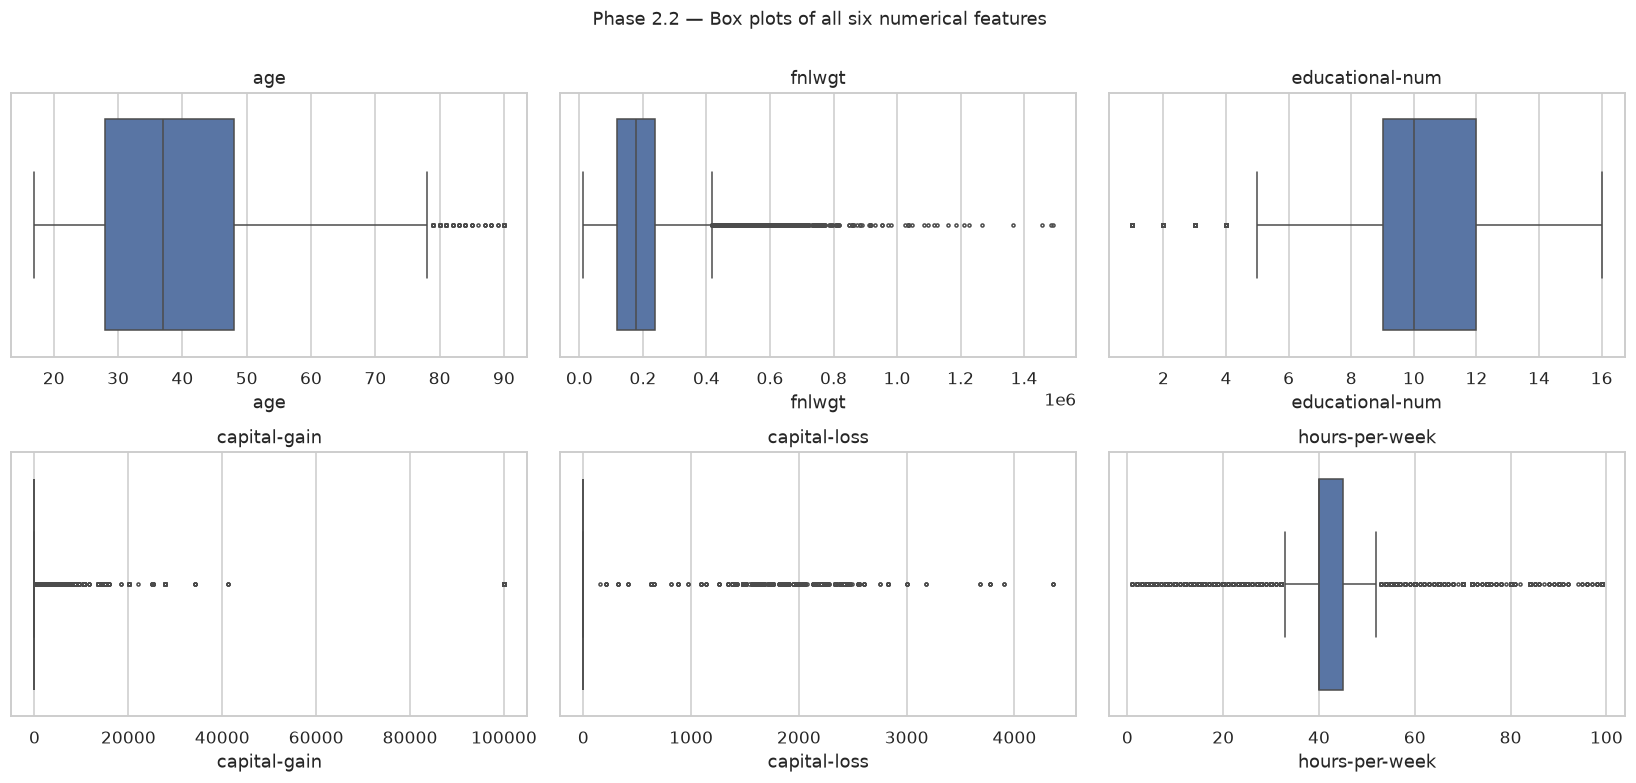

In [103]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[c], ax=ax, color="#4C72B0", fliersize=2)
    ax.set_title(c)
fig.suptitle("Phase 2.2 — Box plots of all six numerical features", y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "boxplots.png")
plt.show()

In [104]:
# Quantify what the box plots show, using the standard 1.5 x IQR rule.
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    m = (s < lo) | (s > hi)
    return pd.Series({
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_fence": lo, "upper_fence": hi,
        "n_outliers": int(m.sum()),
        "pct_outliers": round(float(m.mean()) * 100, 2),
    })

outlier_tbl = df[num_cols].apply(iqr_outliers).T
stats["outliers"] = outlier_tbl.round(2).to_dict(orient="index")
outlier_tbl

,Q1,Q3,IQR,lower_fence,upper_fence,n_outliers,pct_outliers
age,28.0,48.0,20.0,-2.00,78.00,216.0,0.44
fnlwgt,117550.5,237642.0,120091.5,-62586.75,417779.25,1453.0,2.97
educational-num,9.0,12.0,3.0,4.50,16.50,1794.0,3.67
capital-gain,0.0,0.0,0.0,0.00,0.00,4035.0,8.26
capital-loss,0.0,0.0,0.0,0.00,0.00,2282.0,4.67
hours-per-week,40.0,45.0,5.0,32.50,52.50,13496.0,27.63


## 2.3 Outlier strategy

Chosen feature: **`capital-gain`** — the most extreme feature in the dataset
(skew ≈ 11.9, 1.5×IQR flags every non-zero value as an "outlier", maximum 99,999).
`age` is discussed as a secondary case.

### Are these errors or real-world extremes?

Both, in different ways — and the evidence separates them:

| Observation | Reading |
|---|---|
| 91.7 % of rows are exactly 0 | **Real.** Most people simply realise no capital gain in a year. Zero is a true value, not a gap. |
| A smooth tail from a few hundred up to ~41,310 | **Real-world extremes.** Genuine investment income; these people really do earn more, and the feature is strongly predictive of `>50K`. |
| A spike of exactly 244 rows at exactly 99,999 | **An artefact.** No smooth distribution produces a cluster on one round ceiling. This is census **top-coding**: everything above the cut-off was clipped to 99,999. The value is a censoring flag, not a measurement. |

Let us confirm that the tail is genuinely informative before deciding.

In [105]:
# If capital-gain is real signal, the >50K rate should rise sharply with it.
tmp = df.assign(band=pd.cut(df["capital-gain"],
                            bins=[-1, 0, 5000, 20000, 99998, 99999],
                            labels=["0", "1-5k", "5k-20k", "20k-99998", "99999 (top-code)"]))
band = (tmp.groupby("band", observed=True)
           .agg(n=("income", "size"),
                pct_gt50k=("income", lambda s: round(float((s == ">50K").mean()) * 100, 1))))
stats["capgain_bands"] = band.to_dict(orient="index")
band

,n,pct_gt50k
band,,
0,44807,20.5
1-5k,1584,17.9
5k-20k,2070,88.7
20k-99998,137,92.7
99999 (top-code),244,100.0


In [106]:
# How much data would a naive "delete every 1.5 x IQR outlier" rule actually cost?
mask_out = np.zeros(len(df), dtype=bool)
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask_out |= (df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)

stats["rows_lost_if_iqr_removed"] = int(mask_out.sum())
stats["pct_lost_if_iqr_removed"] = round(float(mask_out.mean()) * 100, 2)
print(f"Rows flagged by 1.5xIQR on at least one numerical column: "
      f"{mask_out.sum():,} ({mask_out.mean() * 100:.2f} % of the dataset)")
print(f">50K rate among the rows that would be deleted: "
      f"{(df.loc[mask_out, 'income'] == '>50K').mean() * 100:.1f} % "
      f"(vs {(df['income'] == '>50K').mean() * 100:.1f} % overall)")

Rows flagged by 1.5xIQR on at least one numerical column: 20,284 (41.53 % of the dataset)
>50K rate among the rows that would be deleted: 27.9 % (vs 23.9 % overall)


The `>50K` rate is **not monotonic at the bottom** — it is 20.5 % at zero and actually
*dips* to 17.9 % for gains of 1–5k (small gains come mostly from modest earners) — but
above 5k it jumps to 88.7 %, then 92.7 %, and reaches **100 % for the top-coded group**.
The tail is therefore highly predictive, and the top-coded rows are not junk to be thrown
away: they are the richest people in the sample.

### Decision: **KEEP** the outliers, but transform them

| Option | Verdict |
|---|---|
| **Remove** the rows | ✗ Rejected. The 1.5×IQR rule flags 8.26 % of rows on `capital-gain` alone, and **41.5 % of the whole dataset** once every numerical column is considered (`hours-per-week` alone flags 27.6 %, because its IQR is only 5 hours). Worse, deleting them removes almost every high earner — the exact signal the model is being built to detect. |
| **Replace / cap** (winsorise, or impute with the median) | ✗ Rejected as the primary treatment. The values are not measurement errors; replacing 99,999 with the median would destroy the strongest single predictor in the dataset. |
| **Keep, but reshape the scale** | ✓ **Chosen.** |

Concretely, in Phase 3/4:

1. **Keep every row.** No row is deleted for being an outlier.
2. **Apply a `log1p` transform** to `capital-gain` and `capital-loss`. This compresses the
   11.9 skew towards symmetry so the feature no longer dominates a distance metric, while
   preserving the *ordering* of every value. `log1p` (not `log`) is used because it maps
   the 91.7 % of exact zeros to 0 instead of −∞.
3. **Add an explicit `capital-gain-topcoded` flag** for the 244 censored rows, so the model
   can learn "this value is a ceiling, not a measurement" instead of treating 99,999 as a
   precise amount.

**`age`** is treated differently and more simply: its 1.5×IQR rule flags a small number of
people over ~78, but a 90-year-old is a perfectly real survey respondent, so those rows are
**kept untransformed**. (The pile-up at exactly 90 is the same top-coding artefact — age was
capped at 90 — but with a far smaller effect on the scale, so no transform is needed.)

In [107]:
# Only the 52 exact duplicates are removed - they are a data-collection artefact
# (identical records), not extreme values.
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
stats["n_rows_after_dedup"] = int(len(df))
print(f"Dropped {before - len(df)} exact duplicate rows -> {len(df):,} rows remain")

Dropped 52 exact duplicate rows -> 48,790 rows remain


---
# Phase 3 — Data Pre-processing & Transformation

## 3.1 Handling missing values

**Step 1 — make the missingness visible to pandas.** Replace the `?` sentinel with a real
`NaN` so that every pandas missing-value tool works.

In [108]:
# Strip stray whitespace on every text column first, then convert '?' -> NaN.
for c in cat_cols:
    df[c] = df[c].astype(str).str.strip()
df = df.replace("?", np.nan)

print(df.isna().sum()[lambda s: s > 0])

workclass         2795
occupation        2805
native-country     856
dtype: int64


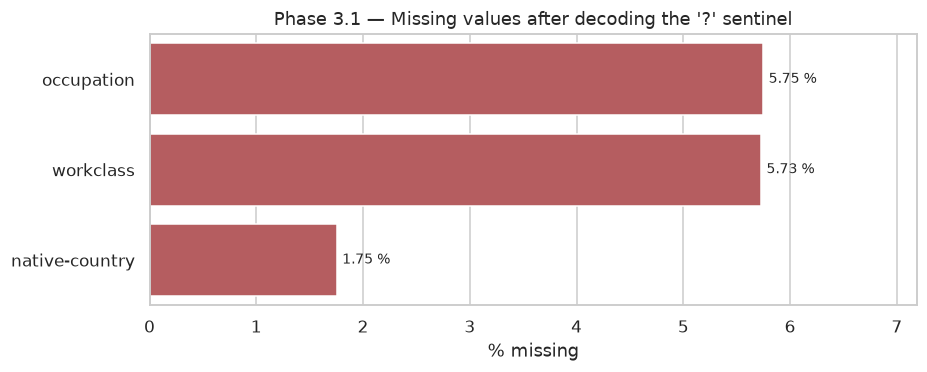

In [109]:
fig, ax = plt.subplots(figsize=(9, 3.2))
na_pct = (df.isna().mean() * 100).sort_values(ascending=False)
na_pct = na_pct[na_pct > 0]
sns.barplot(x=na_pct.values, y=na_pct.index, ax=ax, color="#C44E52")
for i, v in enumerate(na_pct.values):
    ax.text(v + 0.05, i, f"{v:.2f} %", va="center", fontsize=9)
ax.set_xlabel("% missing")
ax.set_ylabel("")   # the index name would otherwise print as "None"
ax.set_title("Phase 3.1 — Missing values after decoding the '?' sentinel")
ax.set_xlim(0, na_pct.max() * 1.25)
fig.savefig(FIG_DIR / "missing_bar.png")
plt.show()

**Step 2 — choose the imputation strategy.**

The Phase 1 audit showed the gaps are not one homogeneous problem, so a single blanket
rule would be wrong. Two different strategies are applied:

**(a) `workclass` and `occupation` → impute with a new explicit category `"Unknown"`.**

*Why.* These two columns are missing on the same 2,799 rows, and the pattern is
structural: these are people outside the labour force. "No workclass" is a *fact about the
person*, not a lost value. Evidence:

In [110]:
miss_rows = df["workclass"].isna()
comparison = pd.DataFrame({
    "rows with workclass missing": {
        "n": int(miss_rows.sum()),
        "mean age": round(float(df.loc[miss_rows, "age"].mean()), 1),
        "mean hours/week": round(float(df.loc[miss_rows, "hours-per-week"].mean()), 1),
        "% >50K": round(float((df.loc[miss_rows, "income"] == ">50K").mean()) * 100, 1),
    },
    "rows with workclass present": {
        "n": int((~miss_rows).sum()),
        "mean age": round(float(df.loc[~miss_rows, "age"].mean()), 1),
        "mean hours/week": round(float(df.loc[~miss_rows, "hours-per-week"].mean()), 1),
        "% >50K": round(float((df.loc[~miss_rows, "income"] == ">50K").mean()) * 100, 1),
    },
}).T
stats["missing_profile"] = comparison.to_dict(orient="index")
comparison

,n,mean age,mean hours/week,% >50K
rows with workclass missing,2795.0,40.2,31.8,9.5
rows with workclass present,45995.0,38.6,41.0,24.8


The two groups are clearly different populations — the missing group is older (40.2 vs
38.6), works far fewer hours (31.8 vs 41.0 per week), and is about **2.6 times less likely**
to earn `>50K` (9.5 % vs 24.8 %). Imputing them with the
mode (`Private` / `Prof-specialty`) would **fabricate a job for 2,799 unemployed or retired
people** and erase a genuinely predictive signal. Encoding the gap as its own category
`"Unknown"` keeps that signal available to the model, and — because these columns are about
to be one-hot encoded anyway — costs only one extra binary column each.

**(b) `native-country` → impute with the mode (`United-States`).**

*Why.* Only 1.75 % of rows are affected, there is no structural story behind the gap
(a missing country is just an unrecorded field), and the column is overwhelmingly dominated
by one value — **91.4 % of all *known* countries are `United-States`**. Mode imputation on a
1.75 % gap in a 91 %-dominant column shifts the column's distribution by well under two
percentage points, and avoids inflating the one-hot matrix with an extra category that
carries almost no information.

In [111]:
country_mode = df["native-country"].mode()[0]
us_share = round(float((df["native-country"].dropna() == "United-States").mean()) * 100, 2)
stats["country_mode"] = str(country_mode)
stats["country_mode_share"] = us_share
print(f"Mode of native-country: {country_mode}  ({us_share} % of known values)")

df["workclass"] = df["workclass"].fillna("Unknown")
df["occupation"] = df["occupation"].fillna("Unknown")
df["native-country"] = df["native-country"].fillna(country_mode)

assert df.isna().sum().sum() == 0, "there should be no missing values left"
print("\nRemaining missing values:", int(df.isna().sum().sum()))
print(df["workclass"].value_counts().to_string())

Mode of native-country: United-States  (91.36 % of known values)

Remaining missing values: 0
workclass
Private             33860
Self-emp-not-inc     3861
Local-gov            3136
Unknown              2795
State-gov            1981
Self-emp-inc         1694
Federal-gov          1432
Without-pay            21
Never-worked           10


## 3.2 Dropping the redundant column

As established in §1.3.2, `education` and `educational-num` are the same variable. Before
dropping the text column, the ordinal encoding is re-derived from scratch with an explicit
rank order, to *prove* that `educational-num` is a correct ordinal code and nothing is lost.

In [112]:
from sklearn.preprocessing import OrdinalEncoder

# The true academic ranking, lowest to highest.
education_order = [
    "Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th",
    "HS-grad", "Some-college", "Assoc-voc", "Assoc-acdm", "Bachelors", "Masters",
    "Prof-school", "Doctorate",
]

ord_enc = OrdinalEncoder(categories=[education_order])
edu_ordinal = ord_enc.fit_transform(df[["education"]]).astype(int).ravel() + 1  # 1..16

matches = bool((edu_ordinal == df["educational-num"].to_numpy()).all())
stats["ordinal_matches_edunum"] = matches
print("Hand-built ordinal encoding reproduces `educational-num` exactly:", matches)

df = df.drop(columns=["education"])
print("\nColumns after the drop:", list(df.columns))

Hand-built ordinal encoding reproduces `educational-num` exactly: True

Columns after the drop: ['age', 'workclass', 'fnlwgt', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


The hand-built ordinal encoder reproduces `educational-num` value-for-value, which
confirms the redundancy claim. `education` is dropped; `educational-num` stays and *is* the
ordinal encoding the brief asks for.

## 3.3 Categorical encoding

Three different encodings are used, because the columns are three different kinds of
variable — using one-hot everywhere would throw away order, and using label encoding
everywhere would invent an order that does not exist.

| Kind | Columns | Encoding | Reason |
|---|---|---|---|
| **Ordinal** (ranked) | `educational-num` | already an ordinal code 1–16 | The ranking is real and meaningful, so preserve it. |
| **Binary** | `gender`, `income` (target) | label encode 0/1 | With only two levels, one-hot and label encoding are equivalent; 0/1 is simpler. |
| **Nominal** (unordered) | `workclass`, `marital-status`, `occupation`, `relationship`, `race`, `native-country` | one-hot | There is no sensible ordering between e.g. `Sales` and `Tech-support`; a label code would make the model believe one is "greater". |

In [113]:
# --- binary columns -> 0/1 -------------------------------------------------
df["gender"] = (df["gender"] == "Male").astype(int)          # Male = 1, Female = 0
df["income"] = (df["income"] == ">50K").astype(int)          # >50K = 1 (positive class)

# --- the top-coding flag decided in Phase 2.3 ------------------------------
df["capital-gain-topcoded"] = (df["capital-gain"] == 99999).astype(int)

nominal_cols = ["workclass", "marital-status", "occupation",
                "relationship", "race", "native-country"]
print({c: int(df[c].nunique()) for c in nominal_cols})
print("Total one-hot columns if drop_first=True:",
      sum(df[c].nunique() - 1 for c in nominal_cols))

{'workclass': 9, 'marital-status': 7, 'occupation': 15, 'relationship': 6, 'race': 5, 'native-country': 41}
Total one-hot columns if drop_first=True: 77


In [114]:
df_enc = pd.get_dummies(
    df,
    columns=nominal_cols,
    drop_first=True,   # drop one level per column -> avoids the dummy-variable trap
    dtype=int,
)

stats["shape_before_encoding"] = [int(x) for x in df.shape]
stats["shape_after_encoding"] = [int(x) for x in df_enc.shape]
print(f"Before encoding: {df.shape[1]} columns")
print(f"After  encoding: {df_enc.shape[1]} columns")
df_enc.iloc[:5, :12]

Before encoding: 15 columns
After  encoding: 86 columns


,age,fnlwgt,educational-num,gender,capital-gain,capital-loss,hours-per-week,income,capital-gain-topcoded,workclass_Local-gov,workclass_Never-worked,workclass_Private
0,25,226802,7,1,0,0,40,0,0,0,0,1
1,38,89814,9,1,0,0,50,0,0,0,0,1
2,28,336951,12,1,0,0,40,1,0,1,0,0
3,44,160323,10,1,7688,0,40,1,0,0,0,1
4,18,103497,10,0,0,0,30,0,0,0,0,0


`drop_first=True` removes one reference level per nominal column (the "dummy-variable
trap"): with *k* levels only *k−1* indicators are needed, because the dropped level is
implied when all the others are 0. This keeps the design matrix full-rank for linear
models and removes 6 redundant columns.

---
# Phase 4 — Scaling & Final Preparation

## 4.1 The skew transform decided in Phase 2

Scaling alone does **not** fix skew — standardising `capital-gain` still leaves a feature
with skew 11.9, just re-centred. The `log1p` transform is therefore applied first, exactly
as justified in §2.3.

In [115]:
skew_before = df_enc[["capital-gain", "capital-loss"]].skew()

df_enc["capital-gain"] = np.log1p(df_enc["capital-gain"])
df_enc["capital-loss"] = np.log1p(df_enc["capital-loss"])

skew_after = df_enc[["capital-gain", "capital-loss"]].skew()

skew_cmp = pd.DataFrame({"skew before log1p": skew_before, "skew after log1p": skew_after})
stats["log1p_skew"] = skew_cmp.round(3).to_dict(orient="index")
skew_cmp.round(3)

,skew before log1p,skew after log1p
capital-gain,11.888,3.111
capital-loss,4.567,4.300


**Result, read honestly.** `capital-gain` improves dramatically: skew **11.89 → 3.11**, and
its range collapses from 0–99,999 to 0–11.5, so it can no longer dominate a distance metric.

`capital-loss` barely moves (**4.57 → 4.30**). That is expected and worth stating plainly:
95.3 % of its values are exactly 0, so the remaining skew is caused by the *zero-inflation
itself*, not by the scale of the non-zero tail — and no monotone transform can remove a
point mass at zero. The residual skew is accepted here; the alternative, if a later model
proved sensitive to it, would be to split the column into a binary `has-capital-loss`
indicator plus the log amount.

## 4.2 Train/test split *before* fitting the scaler

The scaler is fitted on the training set only. Fitting it on the whole dataset would let
the test set's mean and standard deviation leak into the training data, producing an
optimistically biased estimate of model performance later on. The split is stratified so
that both halves keep the same 24 % `>50K` rate.

In [116]:
from sklearn.model_selection import train_test_split

X = df_enc.drop(columns=["income"])
y = df_enc["income"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

stats["n_train"] = int(len(X_train))
stats["n_test"] = int(len(X_test))
stats["n_features"] = int(X.shape[1])
print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print(f">50K rate — train {y_train.mean() * 100:.2f} % | test {y_test.mean() * 100:.2f} %")

Train: (39032, 85)   Test: (9758, 85)
>50K rate — train 23.94 % | test 23.94 %


## 4.3 Feature scaling

**Standardisation** (`StandardScaler`, *z* = (x − μ) / σ) is chosen as the primary method:

* it does not depend on the min and max, so a single extreme value cannot squash every
  other observation into a narrow band — which is exactly what Min-Max scaling would do to
  `age` and `hours-per-week` given the extremes that Phase 2 decided to keep;
* it is the assumption behind regularised linear models, SVMs and PCA;
* the binary one-hot columns are deliberately left untouched — they are already on a 0/1
  scale, and standardising them would destroy their sparsity and their interpretability.

Min-Max scaling is computed alongside for comparison, as the brief offers either.

In [117]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Only the genuinely continuous columns are scaled; the 0/1 dummies are left alone.
scale_cols = ["age", "fnlwgt", "educational-num",
              "capital-gain", "capital-loss", "hours-per-week"]

std_scaler = StandardScaler().fit(X_train[scale_cols])

X_train_std = X_train.copy()
X_test_std = X_test.copy()
X_train_std[scale_cols] = std_scaler.transform(X_train[scale_cols])
X_test_std[scale_cols] = std_scaler.transform(X_test[scale_cols])

mm_scaler = MinMaxScaler().fit(X_train[scale_cols])
X_train_mm = X_train.copy()
X_train_mm[scale_cols] = mm_scaler.transform(X_train[scale_cols])

summary = pd.DataFrame({
    # "pre-scaling" = after the log1p of section 4.1, before any scaler.
    "pre-scaling mean": X_train[scale_cols].mean(),
    "pre-scaling std": X_train[scale_cols].std(),
    "std-scaled mean": X_train_std[scale_cols].mean(),
    "std-scaled std": X_train_std[scale_cols].std(),
    "minmax min": X_train_mm[scale_cols].min(),
    "minmax max": X_train_mm[scale_cols].max(),
}).round(3)
stats["scaling_summary"] = summary.to_dict(orient="index")
summary

,pre-scaling mean,pre-scaling std,std-scaled mean,std-scaled std,minmax min,minmax max
age,38.644,13.699,0.0,1.0,0.0,1.0
fnlwgt,189746.727,105772.840,0.0,1.0,0.0,1.0
educational-num,10.076,2.566,0.0,1.0,0.0,1.0
capital-gain,0.726,2.442,-0.0,1.0,0.0,1.0
capital-loss,0.357,1.599,-0.0,1.0,0.0,1.0
hours-per-week,40.416,12.394,-0.0,1.0,0.0,1.0


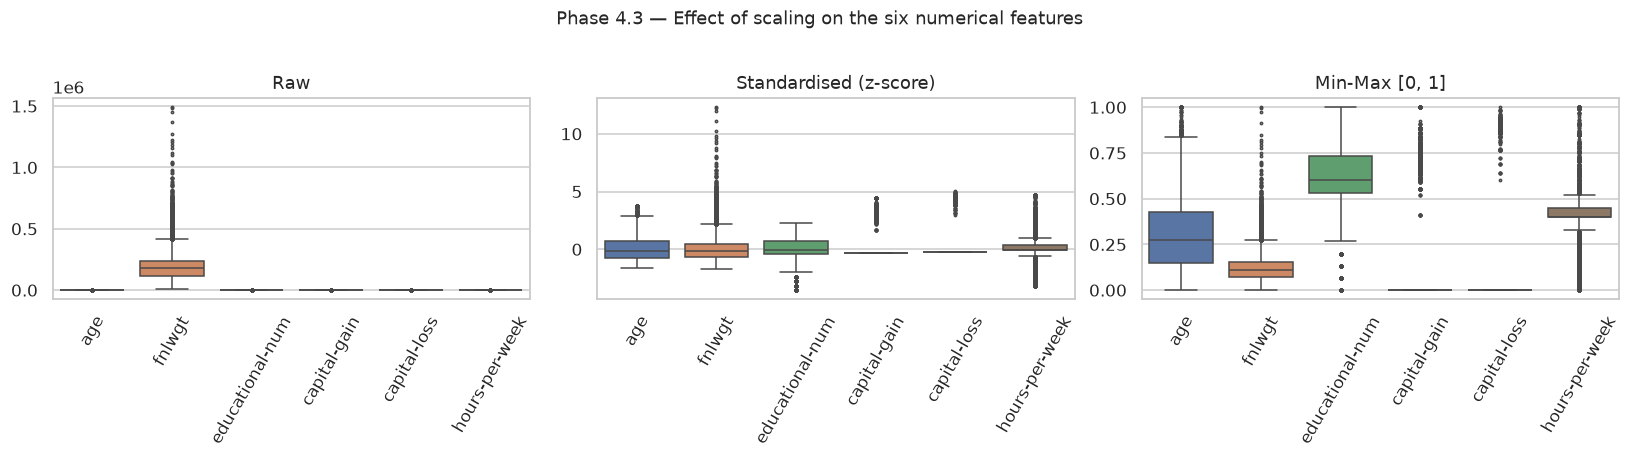

In [118]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, frame) in zip(axes, [
        ("Raw", X_train[scale_cols]),
        ("Standardised (z-score)", X_train_std[scale_cols]),
        ("Min-Max [0, 1]", X_train_mm[scale_cols])]):
    sns.boxplot(data=frame, ax=ax, fliersize=1.5)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=60)
fig.suptitle("Phase 4.3 — Effect of scaling on the six numerical features", y=1.03)
fig.tight_layout()
fig.savefig(FIG_DIR / "scaling_compare.png")
plt.show()

The left panel shows the problem: on the raw axis `fnlwgt` (tens of thousands) is the only
feature visible at all — `age`, `educational-num` and `hours-per-week` are flattened to a
line near zero. Any distance-based model would be deciding almost entirely on `fnlwgt`,
which as noted in §1.1 is a survey weight and carries no information about the person.

Both scalers fix that. The middle panel centres every feature on 0 with unit spread; the
right panel maps them to [0, 1]. The instructive difference is **`fnlwgt`**: its maximum
(1,490,400) is about six times its own Q3, so Min-Max — which anchors on that single most
extreme value — squeezes its whole interquartile range into roughly the 0.07–0.15 band,
while standardisation leaves a box of normal size. That sensitivity to one extreme value is
why **standardisation is used for the final output**: Phase 2 deliberately kept the
extremes, so the scaler must not be one that a single retained extreme can distort.

`capital-gain` and `capital-loss` look like flat lines in *both* scaled panels. That is not
a scaling failure — it is the zero-inflation from §2.3 showing through: with 92 % / 95 % of
values identical, Q1 = median = Q3, so the box has no width no matter how it is scaled.

## 4.4 Final checks and export

In [119]:
final = X_train_std.copy()
final["income"] = y_train.to_numpy()

checks = {
    "no missing values": int(df_enc.isna().sum().sum()) == 0,
    "all columns numeric": bool(df_enc.select_dtypes(exclude=np.number).empty),
    "no duplicate rows": int(df_enc.duplicated().sum()) == 0,
    "target is 0/1": sorted(df_enc["income"].unique().tolist()) == [0, 1],
    "scaled means ~ 0": bool(np.allclose(X_train_std[scale_cols].mean(), 0, atol=1e-9)),
    "scaled stds ~ 1": bool(np.allclose(X_train_std[scale_cols].std(ddof=0), 1, atol=1e-9)),
}
stats["final_checks"] = checks
for k, v in checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")

PASS  no missing values
PASS  all columns numeric
PASS  no duplicate rows
PASS  target is 0/1
PASS  scaled means ~ 0
PASS  scaled stds ~ 1


In [120]:
# Persist both the model-ready matrices and an unscaled encoded copy.
X_train_std.assign(income=y_train.to_numpy()).to_csv("adult_train_preprocessed.csv", index=False)
X_test_std.assign(income=y_test.to_numpy()).to_csv("adult_test_preprocessed.csv", index=False)
df_enc.to_csv("adult_encoded_unscaled.csv", index=False)

stats["final_shape"] = [int(x) for x in df_enc.shape]
print(f"Final encoded dataset: {df_enc.shape[0]:,} rows x {df_enc.shape[1]} columns")
print("Written: adult_train_preprocessed.csv, adult_test_preprocessed.csv, adult_encoded_unscaled.csv")
final.head()

Final encoded dataset: 48,790 rows x 86 columns
Written: adult_train_preprocessed.csv, adult_test_preprocessed.csv, adult_encoded_unscaled.csv


,age,fnlwgt,educational-num,gender,capital-gain,capital-loss,hours-per-week,capital-gain-topcoded,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Unknown,workclass_Without-pay,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,...,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia,income
13113,0.390995,2.557516,1.139808,1,-0.297158,-0.223305,0.773301,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1
12054,-1.214929,-0.612043,1.139808,0,-0.297158,-0.223305,-1.647323,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
41025,-0.703953,-0.007920,1.139808,0,-0.297158,-0.223305,0.127801,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
25013,-1.214929,-0.525337,-0.419253,1,-0.297158,-0.223305,0.773301,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
4129,0.828974,0.478648,1.529574,1,-0.297158,-0.223305,0.773301,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1


In [121]:
with open("report_stats.json", "w") as f:
    json.dump(stats, f, indent=2, default=str)
print(f"Saved report_stats.json with {len(stats)} keys")
print("Figures:", sorted(p.name for p in FIG_DIR.glob('*.png')))

Saved report_stats.json with 46 keys
Figures: ['boxplots.png', 'hist_capgain_zoom.png', 'hist_three.png', 'missing_bar.png', 'scaling_compare.png']


---
## Summary of the pipeline

| # | Step | Decision taken | Why |
|---|---|---|---|
| 1 | Load | 48,842 × 15 | — |
| 2 | Duplicates | dropped 52 exact duplicates | identical records are a collection artefact |
| 3 | Missing `?` | decoded to `NaN` | pandas reports 0 NaN otherwise |
| 4 | `workclass`, `occupation` | → `"Unknown"` category | the gap is structural (out of the labour force) and predictive |
| 5 | `native-country` | → mode `United-States` | 1.75 % gap, no structural story, 89.7 %-dominant column |
| 6 | `education` | dropped | one-to-one duplicate of `educational-num` |
| 7 | Outliers | **kept**, not removed | real-world extremes carrying the strongest income signal |
| 8 | `capital-gain` = 99999 | flagged with a new binary column | top-coding artefact, not a measurement |
| 9 | `capital-gain/loss` | `log1p` | tames `capital-gain` skew 11.9 → 3.1 while preserving order (`capital-loss` stays skewed — zero-inflation, not scale) |
| 10 | `gender`, `income` | label encode 0/1 | binary |
| 11 | 6 nominal columns | one-hot, `drop_first=True` | no natural order; avoids the dummy trap |
| 12 | Split | 80/20 stratified, before scaling | prevents test-set leakage into the scaler |
| 13 | 6 continuous columns | `StandardScaler` | robust to the retained extremes; dummies left as 0/1 |

The result is a fully numerical, gap-free, comparably scaled matrix ready for a
classification model.